# Create computational mesh (bluemesh2d)

Build a gradient-limited element-size field from GEBCO bathymetry and generate
the SnapWave unstructured mesh for the case AoI.

**Prerequisites:** ``01_Generate_tif_From_GEBCO.ipynb`` (topobathy GeoTIFF and AoI).

## Configuration


> **TODO — adapt to bluemesh2d.** The vendored mesher moved from
> `pymesh2d` to `bluemesh2d` and the API evolved. Pending updates in
> the code cells below:
>
> 1. Imports: `from pymesh2d....` → `from bluemesh2d....`
> 2. `getiso_polygone` was renamed to `getiso_polygon` (`geom_util.getiso`)
> 3. `clean_polygon` no longer exists — see
>    `bluemesh2d.geomesh_util.water_polygon.extract_water_polygon`
> 4. `mesh_util.circo.small_flow_centers` no longer exists — see the new
>    `ortho_merge` / `merge_circumcenters` / `smood` workflow
>    (and the higher-level `bluemesh2d.pipeline` / `bluemesh2d.meshgen`)


In [ ]:
import rioxarray
from utils.config import PATHS, resolve

topobathy = rioxarray.open_rasterio(resolve(PATHS["topobathy_file"])).sortby(
    "x", ascending=False
)
topobathy

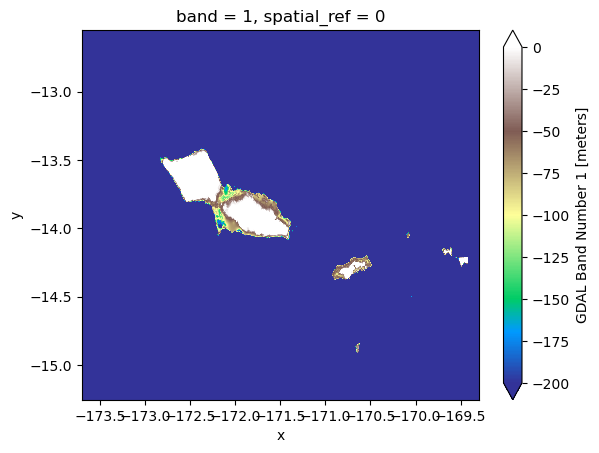

In [2]:
topobathy.plot(vmin=-200, vmax=0, cmap="terrain")

In [3]:
import pyproj
from bluemesh2d.geom_util.proj_util import get_local_utm_crs

topobathy_crs = pyproj.CRS.from_epsg(4326)
utm_crs = get_local_utm_crs(topobathy_crs, topobathy.x, topobathy.y)

topobathy_crs, utm_crs

(<Geographic 2D CRS: EPSG:4326>
 Name: WGS 84
 Axis Info [ellipsoidal]:
 - Lat[north]: Geodetic latitude (degree)
 - Lon[east]: Geodetic longitude (degree)
 Area of Use:
 - name: World.
 - bounds: (-180.0, -90.0, 180.0, 90.0)
 Datum: World Geodetic System 1984 ensemble
 - Ellipsoid: WGS 84
 - Prime Meridian: Greenwich,
 <Projected CRS: PROJCS["UTM local",GEOGCS["WGS 84",DATUM["WGS_1984 ...>
 Name: UTM local
 Axis Info [cartesian]:
 - E[east]: Easting (metre)
 - N[north]: Northing (metre)
 Area of Use:
 - undefined
 Coordinate Operation:
 - name: unnamed
 - method: Transverse Mercator
 Datum: World Geodetic System 1984
 - Ellipsoid: WGS 84
 - Prime Meridian: Greenwich)

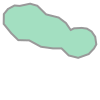

In [4]:
import geopandas as gpd

aoi_polygon = gpd.read_file(resolve(PATHS["aoi_file"])).loc[0, "geometry"]
aoi_polygon

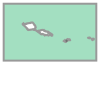

In [5]:
from bluemesh2d.geom_util.getiso import getiso_polygon
from shapely import make_valid
from shapely.geometry import MultiPolygon

# Extract coastline (ocean area)
polygon_cost = getiso_polygon(
    topobathy.x, topobathy.y, topobathy.squeeze().values, zmax=0.0
)
# Extract the area of the domain
polygon_indef = getiso_polygon(
    topobathy.x, topobathy.y, topobathy.squeeze().values, zmax=5000
)

# Make the polygons valid
cost_mp = make_valid(MultiPolygon(polygon_cost)).buffer(0)
indef_mp = make_valid(MultiPolygon(polygon_indef)).buffer(0)

# Intersect the polygons to get the domain
topobathy_dominio = make_valid(cost_mp.intersection(indef_mp)).buffer(0)
# topobathy_dominio = max(topobathy_dominio_prev.geoms, key=lambda p: p.area)

topobathy_dominio

In [6]:
aoi_topobathy_polygon = aoi_polygon.intersection(topobathy_dominio)

# export aoi_topobathy_plygon
gdf = gpd.GeoDataFrame(geometry=[aoi_topobathy_polygon], crs=topobathy_crs)
# gdf.to_file("inputs/AoI_Polygons/AoI_topobathy.shp")

In [ ]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})

topobathy.isel(x=slice(None, None, 100), y=slice(None, None, 100)).plot(
    vmin=-200, vmax=0, cmap="terrain", ax=ax
)
gdf.plot(ax=ax, color="red", alpha=0.25, edgecolor="red")

In [8]:
from bluemesh2d.geomesh_util.depth_field import depth_field_from_tif
from bluemesh2d.hfun_util.make_depth_hfun import make_depth_hfun

depth_field = depth_field_from_tif(str(resolve(PATHS["topobathy_file"])), utm_crs)

hfun = make_depth_hfun(
    depth_field,
    hmin=100.0,
    hmax=1000.0,
    detail=None,
    detail_hmin=50.0,
    slope_ncells=15,
    slope_step=500.0,
)

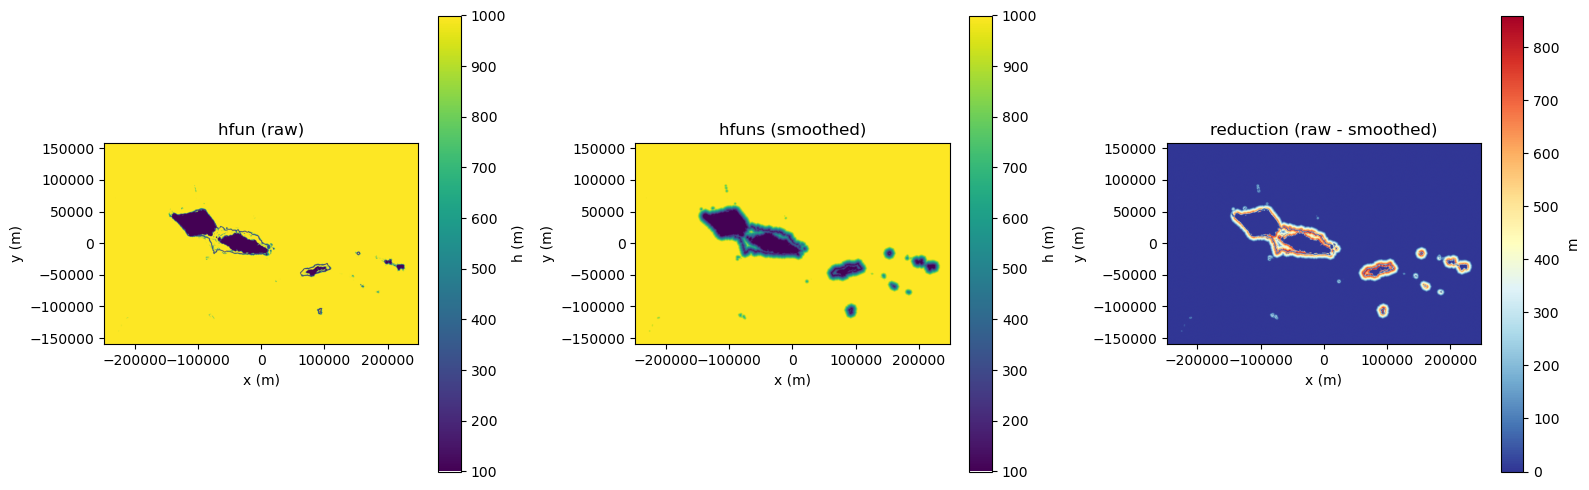

In [9]:
from bluemesh2d.hfun_util.smooth_and_precomput import smooth_precomput_hfun

hfun_path = smooth_precomput_hfun(hfun, max_gradient=0.1, plot=True)

In [10]:
from bluemesh2d.geom_util.proj_util import reproject_geometry

domain_UTM = reproject_geometry(aoi_topobathy_polygon, topobathy_crs, utm_crs)

if domain_UTM.geom_type == "MultiPolygon":
    largest_polygon_domain_UTM = max(domain_UTM.geoms, key=lambda p: p.area)
else:
    largest_polygon_domain_UTM = domain_UTM

In [11]:
from bluemesh2d.geom_util.poly_util import polygon_to_node_edge, resample_polygon_hfun

# Use smoothed sizing function directly
poly_comput_UTM = resample_polygon_hfun(largest_polygon_domain_UTM, hfun_path)

if poly_comput_UTM.geom_type == "MultiPolygon":
    poly_comput_UTM = max(poly_comput_UTM.geoms, key=lambda p: p.area)

# Convert to nodes and edges
node_c, edge_c = polygon_to_node_edge(poly_comput_UTM)

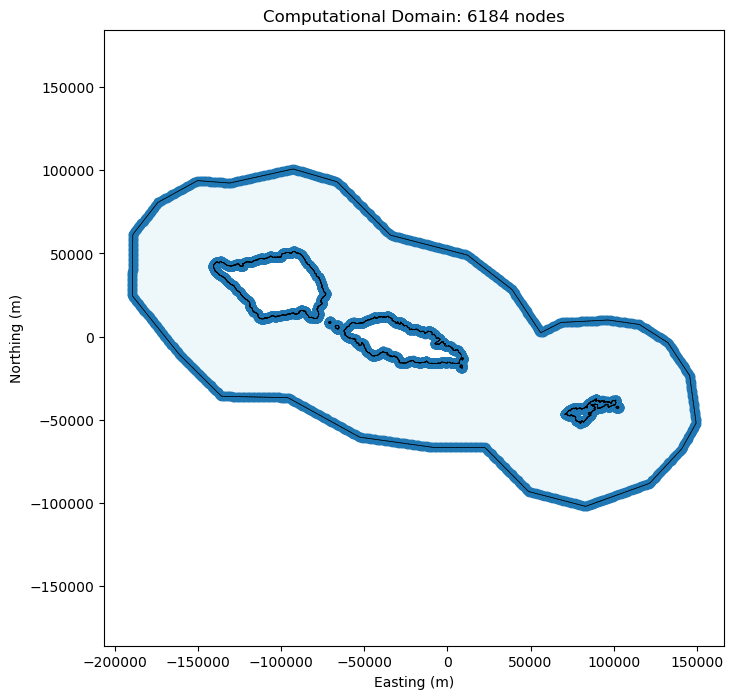

In [12]:
from shapely.plotting import plot_polygon

fig, ax = plt.subplots(figsize=(8, 8))
plot_polygon(poly_comput_UTM, ax=ax, facecolor="lightblue", alpha=0.2)

for e in edge_c.astype(int):
    ax.plot(node_c[e, 0], node_c[e, 1], "k-", lw=0.5)
ax.scatter(node_c[:, 0], node_c[:, 1], color="red", s=2)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title(f"Computational Domain: {len(node_c)} nodes")
ax.axis("equal");

In [13]:
from bluemesh2d.refine import refine

# Mesh generation options
opts_refine = {"kind": "delaunay"}

# Generate and smooth computational mesh
vert, etri, tria, tnum = refine(node_c, edge_c, [], opts_refine, hfun_path)


 Refine triangulation...

 -------------------------------------------------------
      |ITER.|          |CDT1(X)|          |CDT2(X)|     
 -------------------------------------------------------
          1               6184               6200
         10               6184              16902
         20               6184             129728
         30               6184             281082
         40               6184             295738
         41               6184             295740



In [14]:
from bluemesh2d.smooth import smooth

opts_smooth = {}

vert, etri, tria, tnum = smooth(vert, etri, tria, tnum, opts_smooth, hfun_path)


 Smooth triangulation...

 -------------------------------------------------------
      |ITER.|          |MOVE(X)|          |DTRI(X)|     
 -------------------------------------------------------
          0             139904             301416
          4             129245             282218
          8             106902             276060
         12              69772             273386
         16              42329             272282
         20              28580             271806
         24              21964             271578
         28              18584             271514



In [15]:
from bluemesh2d.geom_util.proj_util import reproject_node

# from pymesh2d.smood import smood

vert_geo = reproject_node(
    vert, get_local_utm_crs(topobathy_crs, topobathy.x, topobathy.y), topobathy_crs
)

In [16]:
from bluemesh2d.geomesh_util.interpolation_mesh import interpolate_from_tiff

z = interpolate_from_tiff(
    str(resolve(PATHS["topobathy_file"])), vert_geo, input_crs=topobathy_crs
)

In [17]:
import numpy as np
from bluemesh2d.geomesh_util.grd_util import adcirc2DFlowFM

ds_out = adcirc2DFlowFM(np.column_stack((vert_geo, z)), tria)

In [18]:
ds_out.to_netcdf(resolve(PATHS["mesh_file"]))